In [1]:
# load the German Credit data and take a first look
import pandas as pd
df = pd.read_csv("../data/german_credit.csv")
print(df.shape)
df.head()

(1000, 21)


,Creditability,Account Balance,Duration of Credit (month),Payment Status of Previous Credit,Purpose,Credit Amount,Value Savings/Stocks,Length of current employment,Instalment per cent,Sex & Marital Status,...,Duration in Current address,Most valuable available asset,Age (years),Concurrent Credits,Type of apartment,No of Credits at this Bank,Occupation,No of dependents,Telephone,Foreign Worker
0,1,1,18,4,2,1049,1,2,4,2,...,4,2,21,3,1,1,3,1,1,1
1,1,1,9,4,0,2799,1,3,2,3,...,2,1,36,3,1,2,3,2,1,1
2,1,2,12,2,9,841,2,4,2,2,...,4,1,23,3,1,1,2,1,1,1
3,1,1,12,4,0,2122,1,3,3,3,...,2,1,39,3,1,2,2,2,1,2
4,1,1,12,4,0,2171,1,3,4,3,...,4,2,38,1,2,2,2,1,1,2


In [2]:
# check column types, missing values and duplicates
df.info()
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   Creditability                      1000 non-null   int64
 1   Account Balance                    1000 non-null   int64
 2   Duration of Credit (month)         1000 non-null   int64
 3   Payment Status of Previous Credit  1000 non-null   int64
 4   Purpose                            1000 non-null   int64
 5   Credit Amount                      1000 non-null   int64
 6   Value Savings/Stocks               1000 non-null   int64
 7   Length of current employment       1000 non-null   int64
 8   Instalment per cent                1000 non-null   int64
 9   Sex & Marital Status               1000 non-null   int64
 10  Guarantors                         1000 non-null   int64
 11  Duration in Current address        1000 non-null   int64
 12  Most valuable available asset   

In [4]:
# group the columns by variable type (this decides which statistical test we use)
target = "Creditability"

numeric = ["Duration of Credit (month)", "Credit Amount", "Age (years)",
           "No of Credits at this Bank", "No of dependents"]

ordinal = ["Length of current employment", "Instalment per cent",
           "Duration in Current address", "Occupation"]

nominal = ["Account Balance", "Payment Status of Previous Credit", "Purpose",
           "Value Savings/Stocks", "Sex & Marital Status", "Guarantors",
           "Most valuable available asset", "Concurrent Credits",
           "Type of apartment", "Telephone", "Foreign Worker"]

print("Numeric:", len(numeric), "| Ordinal:", len(ordinal), "| Nominal:", len(nominal))
print("Total features:", len(numeric) + len(ordinal) + len(nominal))

Numeric: 5 | Ordinal: 4 | Nominal: 11
Total features: 20


In [8]:
# descriptive statistics for the numeric columns, plus median, skewness and CV
desc = df[numeric].describe().T
desc["median"] = df[numeric].median()
desc["skew"] = df[numeric].skew()
desc["cv_%"] = desc["std"] / desc["mean"] * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,median,skew,cv_%
Duration of Credit (month),1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0,18.0,1.09,57.69
Credit Amount,1000.0,3271.25,2822.75,250.0,1365.5,2319.5,3972.25,18424.0,2319.5,1.95,86.29
Age (years),1000.0,35.54,11.35,19.0,27.0,33.0,42.00,75.0,33.0,1.02,31.94
No of Credits at this Bank,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0,1.0,1.27,41.06
No of dependents,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0,1.0,1.91,31.35


## Data quality and descriptive statistics

- Missing values: 0 · Duplicate rows: 0
- Credit Amount is strongly right-skewed (skew = 1.95): mean 3271.25 DM vs median 2319.5 DM, so we report the median.
- Credit Amount varies the most (CV =86.29%): loans range from small to very large.
- Duration and Age are also right-skewed (skew ≈ 1.09 and 1.02).
- All numeric variables are skewed, so we expect them NOT to be bell shaped → we'll test with Shapiro-Wilk next.

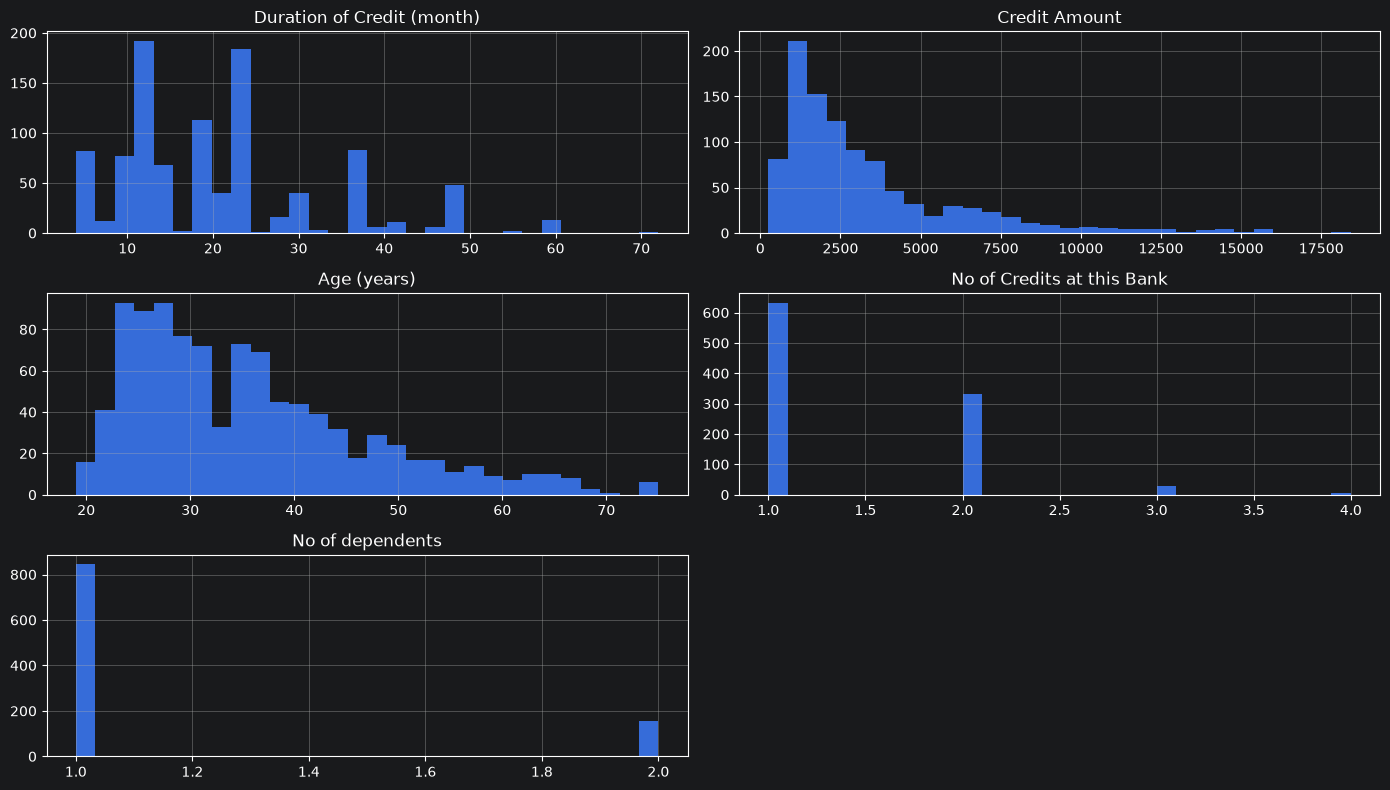

In [9]:
# histograms of the numeric columns to see their shape
import matplotlib.pyplot as plt
df[numeric].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

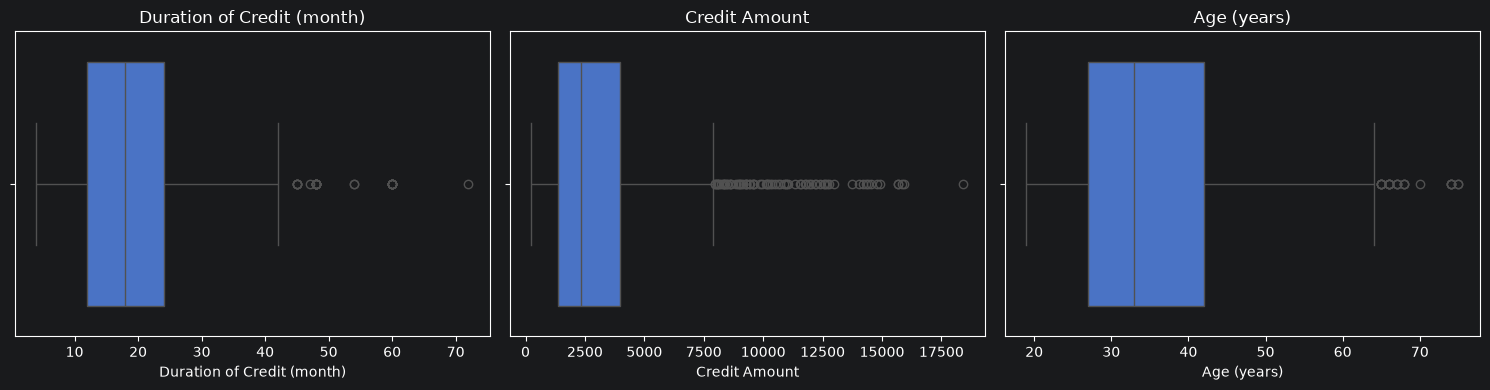

In [10]:
# box plots of the 3 continuous variables to spot outliers
import seaborn as sns
continuous = ["Duration of Credit (month)", "Credit Amount", "Age (years)"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, continuous):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [11]:
# count outliers with the IQR rule (above Q3 + 1.5 x IQR)
for col in continuous:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    n_out = (df[col] > upper).sum()
    print(f"{col}: Q1={q1}, Q3={q3}, IQR={iqr}, upper fence={upper}, outliers={n_out}")

Duration of Credit (month): Q1=12.0, Q3=24.0, IQR=12.0, upper fence=42.0, outliers=70
Credit Amount: Q1=1365.5, Q3=3972.25, IQR=2606.75, upper fence=7882.375, outliers=72
Age (years): Q1=27.0, Q3=42.0, IQR=15.0, upper fence=64.5, outliers=23


In [14]:
# flag outliers and compare their bad-credit rate with everyone else
for col in continuous:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    upper = q3 + 1.5 * (q3 - q1)
    is_outlier = df[col] > upper
    bad_out = (df.loc[is_outlier, "Creditability"] == 0).mean() * 100
    bad_rest = (df.loc[~is_outlier, "Creditability"] == 0).mean() * 100
    print(f"{col}: bad rate outliers = {bad_out:.1f}%, rest = {bad_rest:.1f}%")

Duration of Credit (month): bad rate outliers = 57.1%, rest = 28.0%
Credit Amount: bad rate outliers = 54.2%, rest = 28.1%
Age (years): bad rate outliers = 26.1%, rest = 30.1%


## Outliers (IQR rule)

| Variable | Upper fence | Outliers | Bad rate (outliers) | Bad rate (rest) |
|---|---|---|---|---|
| Duration | 42 months | 70 | 57.1% | 28.0% |
| Credit Amount | 7,882 DM | 72 | 54.2% | 28.1% |
| Age | 64.5 years | 23 | 26.1% | 30.1% |

- All outliers are real customers, not errors.
- Very long and very large loans are about twice as risky as the rest, so the outliers carry key information.
- **Decision: keep all outliers**, and use methods that are robust to them (median, rank tests, decision trees).

In [16]:
# class balance: how many good (1) vs bad (0) customers
print(df["Creditability"].value_counts())
print(df["Creditability"].value_counts(normalize=True) * 100)

Creditability
1    700
0    300
Name: count, dtype: int64
Creditability
1    70.0
0    30.0
Name: proportion, dtype: float64


## Class balance

- Good credit (1): 700 (70%) · Bad credit (0): 300 (30%), so the classes are imbalanced.
- A model that predicts "good" for everyone already gets 70% accuracy while catching no bad customers, so accuracy alone is misleading.
- Next steps: stratified split, FP rate / AUC / cost matrix, and balancing techniques.